In [12]:
import numpy as np
import random
random.seed(42)
np.random.seed(42)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
from nltk.corpus import stopwords
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
confusion_matrix, f1_score, recall_score, precision_score)
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler

from imblearn.over_sampling import SMOTE

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from torch.optim import AdamW
from transformers import get_scheduler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import CountVectorizer

import shap
from lime.lime_text import LimeTextExplainer

!pip install textstat -q

from textblob import TextBlob
import textstat
import spacy

from sklearn.manifold import TSNE

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
from sklearn.metrics import roc_curve

In [13]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

df = pd.read_csv('/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv')

print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 3 rows:")
df.head(3)

Shape: (17880, 18)

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

First 3 rows:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu...",Experience with content management systems a major plus (any blogging counts!)Familiar with the ...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Secon...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience work...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies across the Private ...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assis...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activi...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


# EDA

### Class Distribution & Missing Values

Exploratory data analysis begins with understanding the target variable distribution and data completeness. Given the nature of fraud detection, class imbalance is expected and will directly influence modeling decisions.

In [14]:
print("Fraudulent distribution:")
print(df['fraudulent'].value_counts())
print("\nPercentage:")
print(df['fraudulent'].value_counts(normalize=True).round(3) * 100)

print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False))


Fraudulent distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Percentage:
fraudulent
0    95.2
1     4.8
Name: proportion, dtype: float64

Missing values per column:
salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64


The dataset is highly imbalanced, with only 4.8% of postings labeled as fraudulent (866 out of 17,880). Multiple techniques will be explored and compared to determine the most effective approach. Additionally, several columns exhibit significant missingness - most notably salary_range (84%), department (65%), and required_education (45%), which may itself be informative if fraudulent postings omit structured information more often than genuine ones.


### Text & Visual Analysis

Visual analysis of text length and categorical distributions provides intuition about structural differences between real and fraudulent postings, patterns that will later inform feature engineering decisions.

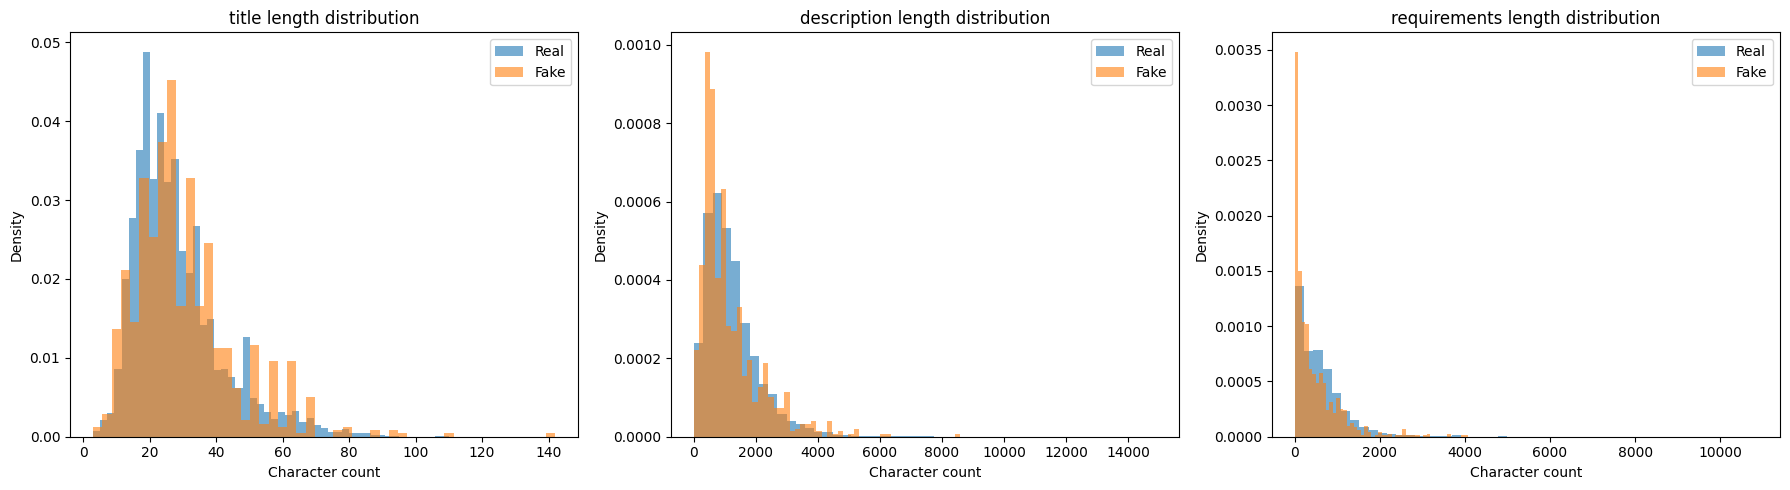

In [15]:
# Text length analysis
text_cols = ['title', 'description', 'requirements']

for col in text_cols:
    df[col + '_len'] = df[col].fillna('').apply(len)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(text_cols):
    for label, group in df.groupby('fraudulent'):
        axes[i].hist(group[col + '_len'], bins=50, alpha=0.6, 
                     label='Fake' if label == 1 else 'Real', density=True)
    axes[i].set_title(f'{col} length distribution')
    axes[i].set_xlabel('Character count')
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.show()


Text length distributions reveal structural differences between real and fraudulent postings. 
1. All three fields are right-skewed, with most postings concentrated at shorter lengths.
2. Fake postings have a somewhat heavier tail of longer titles (roughly 40–70 characters).
3. Fake and real descriptions overlap heavily, with only a small difference near the lowest lengths.
4. Fake postings show a pronounced spike at very short or zero-length requirements. Since missing values are counted as length 0, part of this spike may reflect empty fields rather than short text.

Length-based features are therefore worth testing in the modeling phase, particularly for requirements.

### Word Clouds: Real vs Fake Postings

Word clouds visualize the most frequent terms in real and fraudulent job descriptions, offering a first look at the linguistic patterns that distinguish the two classes.

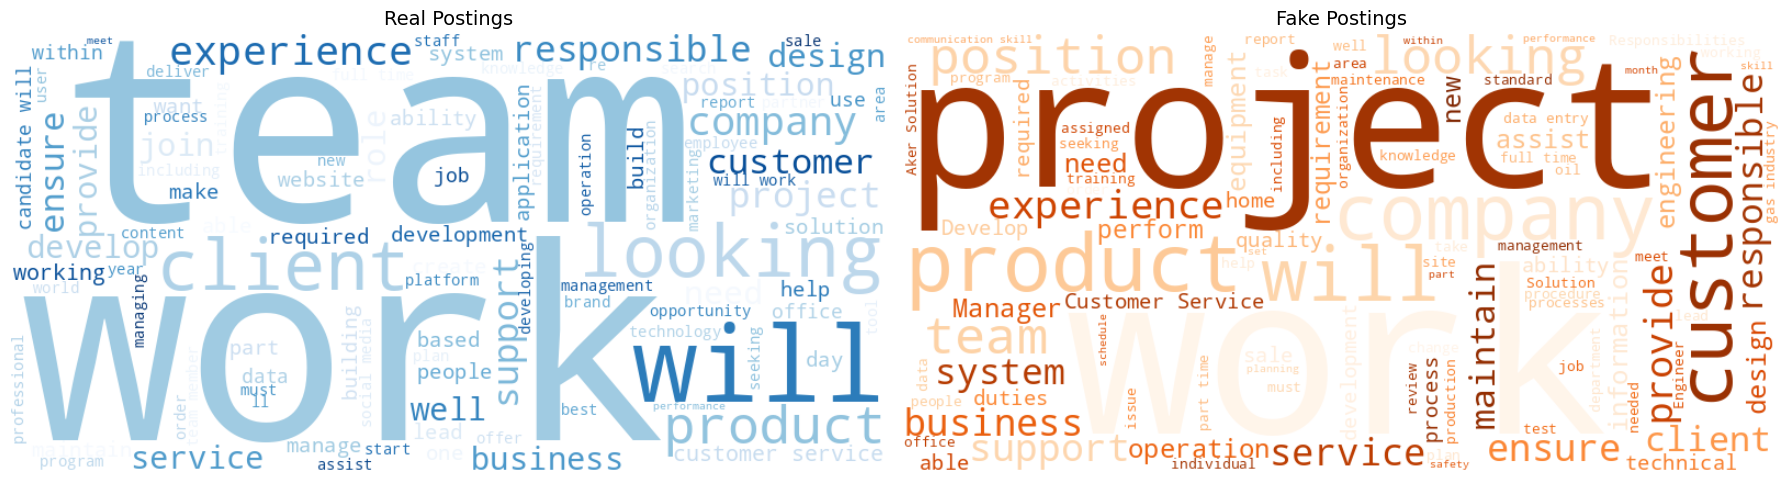

In [16]:
real_text = ' '.join(df[df['fraudulent'] == 0]['description'].fillna(''))
fake_text = ' '.join(df[df['fraudulent'] == 1]['description'].fillna(''))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

wc_real = WordCloud(width=800, height=400, background_color='white', 
                    max_words=100, colormap='Blues').generate(real_text)
wc_fake = WordCloud(width=800, height=400, background_color='white', 
                    max_words=100, colormap='Oranges').generate(fake_text)

axes[0].imshow(wc_real, interpolation='bilinear')
axes[0].set_title('Real Postings', fontsize=14)
axes[0].axis('off')

axes[1].imshow(wc_fake, interpolation='bilinear')
axes[1].set_title('Fake Postings', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

Word clouds highlight distinct linguistic patterns between the two classes. 
- Both classes share many of the largest terms (“work”, “looking”, “customer”, “product”, “company”). Real postings stand out mainly for “team” and for web and marketing vocabulary (“website”, “platform”, “marketing”, “social media”, “technology”).
- Fake postings stand out for “project” and for industrial or technical vocabulary (“engineering”, “equipment”, “maintenance”, “oil”, “gas industry”), as well as phrases typical of low-barrier jobs such as “data entry” and “part time”.

Word clouds show frequency rather than discriminative power, and the strong overlap suggests that raw word counts alone are insufficient for classification.

### Categorical Distributions

Examining categorical features across real and fraudulent postings reveals whether structural metadata, such as employment type, experience level, or company branding, differs systematically between the two classes.

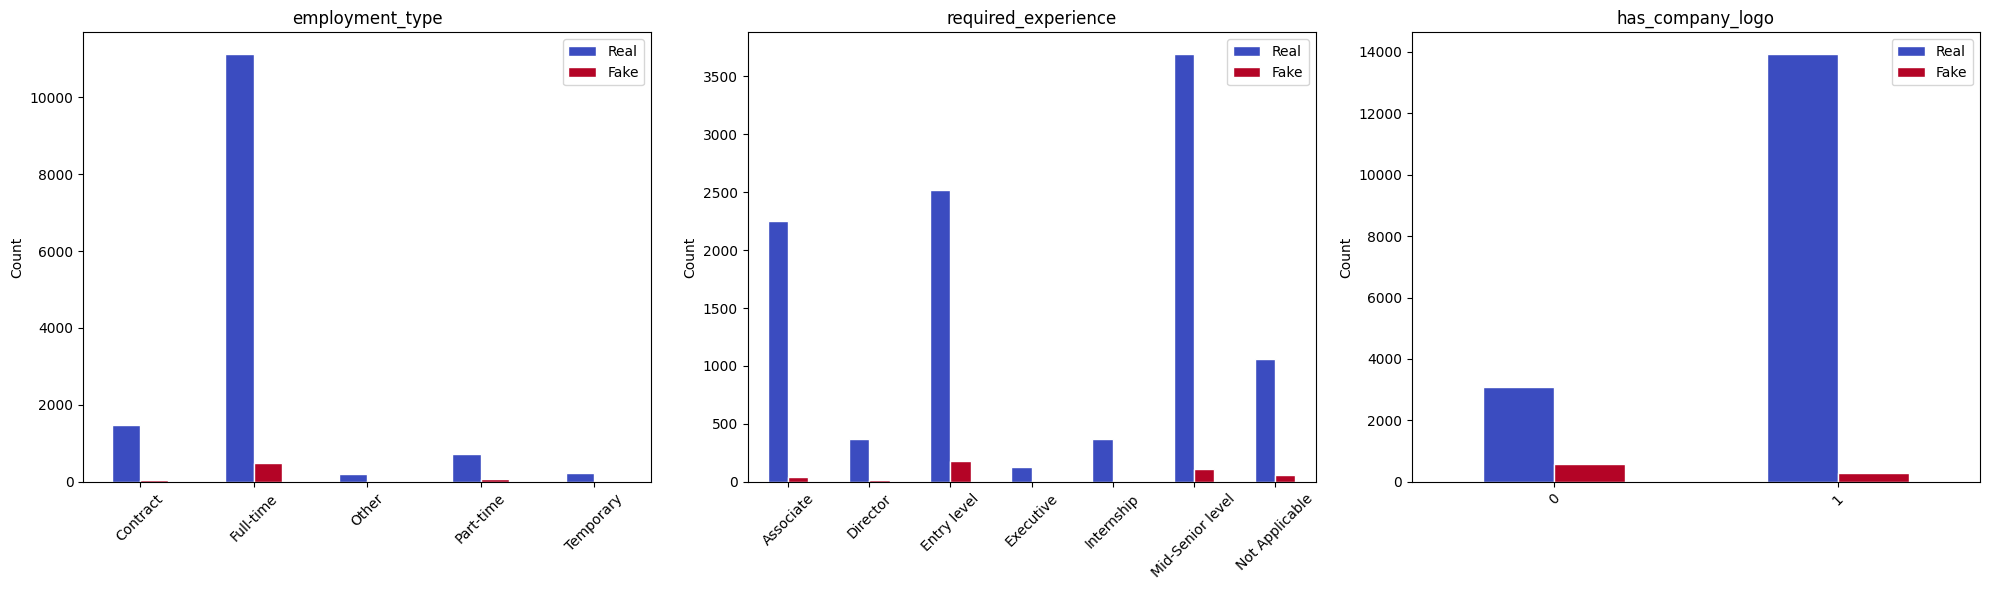

In [17]:
cat_cols = ['employment_type', 'required_experience', 'has_company_logo']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(cat_cols):
    temp = df.groupby([col, 'fraudulent']).size().unstack(fill_value=0)
    temp.columns = ['Real', 'Fake']
    temp.plot(kind='bar', ax=axes[i], colormap='coolwarm', edgecolor='white')
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.tight_layout()
plt.show()


The bar charts show raw counts, and because real postings outnumber fake ones roughly 20 to 1, they show where each class is concentrated rather than which categories are riskier.

- Employment type: both classes are concentrated in full-time positions. The fake bars for the other types are too small to read at this scale, so no conclusion can be drawn about them.
- Required experience: fake postings are most visible at entry level and mid-senior level, roughly mirroring where real postings are concentrated. No fake postings are visible for director and executive roles, although these categories are small overall.
- Company logo: this is the clearest difference. Approximately two thirds of fake postings have no logo, compared with less than a fifth of real ones; roughly 15% of postings without a logo are fake, versus about 2% of those with one.

Company logo is therefore the most promising of the three features, while employment type and experience level show little visible separation between the classes.

### Text Preprocessing

Before modeling, the text fields (title, company profile, description and requirements) are combined into a single input and cleaned: HTML tags, punctuation, digits and English stopwords are removed and the text is lowercased.

In [18]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text)
    text = re.sub(r'<.*?>', ' ', text)
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    text = ' '.join([w for w in text.split() if w not in stop_words])
    return text

text_cols = ['title', 'company_profile', 'description', 'requirements']
df['combined_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)
df['clean_text'] = df['combined_text'].apply(clean_text)

#example
print("Original text sample:")
print(df['combined_text'].iloc[0][:300])
print("\nCleaned text sample:")
print(df['clean_text'].iloc[0][:300])

print("\nAverage token count after cleaning:")
print(df['clean_text'].apply(lambda x: len(x.split())).mean().round(1))

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Original text sample:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and 

Cleaned text sample:
marketing intern food created groundbreaking award winning cooking site support connect celebrate home cooks give everything need one place top editorial business engineering team focused using technology find new better ways connect people around specific food interests offer superb highly curated 

Average token count after cleaning:
233.6


Text preprocessing consolidates four fields into a single cleaned input per posting, with an average of 233.6 tokens after stopword removal. The pipeline removes HTML tags, punctuation, digits and English stopwords, and lowercases the text. This representation is used for both TF-IDF and DistilBERT.

Two limitations are worth noting. First, the standard NLTK stopword list includes negations such as “no” and “not”, and digit removal discards numbers such as salaries, so some potentially informative content is lost. Second, transformer models are usually trained on natural text, so a lighter cleaning step (keeping punctuation and stopwords) could suit DistilBERT better; with an average of about 234 words, longer postings are also truncated at 256 tokens. Testing lighter preprocessing for DistilBERT is left as future work.

### Feature Engineering

Beyond raw text, structural metadata carries predictive signal. Numerical and binary features are derived from both the text content and the posting's structural characteristics, providing the baseline model with a richer input representation.

In [19]:
df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))
df['avg_word_length'] = df['clean_text'].apply(lambda x: np.mean([len(w) for w in x.split()]) if len(x.split()) > 0 else 0)
df['upper_count'] = df['combined_text'].apply(lambda x: sum(1 for c in x if c.isupper()))

df['has_salary'] = df['salary_range'].notna().astype(int)
df['has_company_profile'] = df['company_profile'].notna().astype(int)
df['has_requirements'] = df['requirements'].notna().astype(int)
df['has_benefits'] = df['benefits'].notna().astype(int)

df['employment_type_enc'] = df['employment_type'].fillna('Unknown')
df['required_experience_enc'] = df['required_experience'].fillna('Unknown')
df['required_education_enc'] = df['required_education'].fillna('Unknown')

from sklearn.preprocessing import LabelEncoder
for col in ['employment_type_enc', 'required_experience_enc', 'required_education_enc']:
    df[col] = LabelEncoder().fit_transform(df[col])

feature_cols = ['word_count', 'avg_word_length', 'upper_count', 
                'has_salary', 'has_company_profile', 'has_requirements', 
                'has_benefits', 'telecommuting', 'has_company_logo', 
                'has_questions', 'employment_type_enc', 
                'required_experience_enc', 'required_education_enc']

print("Feature summary:")
print(df[feature_cols + ['fraudulent']].groupby('fraudulent').mean().round(3))

Feature summary:
            word_count  avg_word_length  upper_count  has_salary  \
fraudulent                                                         
0              236.257            6.937       83.900       0.155   
1              181.244            6.865       77.952       0.258   

            has_company_profile  has_requirements  has_benefits  \
fraudulent                                                        
0                         0.840             0.851         0.598   
1                         0.322             0.822         0.580   

            telecommuting  has_company_logo  has_questions  \
fraudulent                                                   
0                   0.041             0.819          0.502   
1                   0.074             0.327          0.289   

            employment_type_enc  required_experience_enc  \
fraudulent                                                 
0                         1.812                    4.608   
1           

Group means of the engineered features show several clear differences between real and fraudulent postings.

1. Company profile and logo show the largest gaps: real postings include a company profile in 84.0% of cases versus 32.2% for fake ones, and a logo in 81.9% versus 32.7%.
2. Screening questions are more common in real postings (50.2% vs 28.9%).
3. Salary range is more often present in fake postings (25.8% vs 15.5%), and telecommuting is almost twice as frequent (7.4% vs 4.1%).
4. Real postings contain on average about 55 more tokens than fake ones (236.3 vs 181.2). Since the cleaned text includes the company profile, which most fake postings lack, part of this gap is a direct consequence of missing fields.

The averages of the label-encoded categorical columns are not interpretable as such, since the codes follow alphabetical order. These differences are descriptive only; their predictive value is assessed in the modeling stage.

### Train / Test Split
The dataset is split 80/20 into training and test sets using stratified sampling, which preserves the class distribution (4.8% fraudulent) in both subsets. The test set (3,576 postings) is kept untouched until final evaluation. For DistilBERT, a validation set is further carved out of the training set (15%) and used for early stopping.

The split is random at posting level. Near-duplicate postings, which the phrase analysis below suggests may exist, were not checked for; they could appear in both sets and make the test results slightly optimistic.

In [20]:
X_text = df['clean_text']
X_meta = df[feature_cols].values
y = df['fraudulent']

X_train_text, X_test_text, X_train_meta, X_test_meta, y_train, y_test = train_test_split(
    X_text, X_meta, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", len(X_train_text))
print("Test size:", len(X_test_text))
print("Train fraud rate:", y_train.mean().round(3))
print("Test fraud rate:", y_test.mean().round(3))

Train size: 14304
Test size: 3576
Train fraud rate: 0.048
Test fraud rate: 0.048


### Baseline Model: TF-IDF

A TF-IDF representation of the cleaned text (unigrams to trigrams, up to 10,000 features), combined with the engineered structural features, serves as the input for three baseline classifiers: Logistic Regression, Random Forest and a calibrated LinearSVC. This benchmark provides a reference point for the more advanced model that follows.

In [21]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1,3))
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

X_train_meta = df.loc[X_train_text.index, feature_cols].values
X_test_meta = df.loc[X_test_text.index, feature_cols].values

X_train_combined = hstack([X_train_tfidf, csr_matrix(X_train_meta)])
X_test_combined = hstack([X_test_tfidf, csr_matrix(X_test_meta)])

In [22]:
scaler = MaxAbsScaler()
X_train_combined_scaled = scaler.fit_transform(X_train_combined)
X_test_combined_scaled = scaler.transform(X_test_combined)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    'LinearSVC': CalibratedClassifierCV(LinearSVC(class_weight='balanced', max_iter=1000, random_state=42))
}

for name, model in models.items():
    X_tr = X_train_combined_scaled if name == 'Logistic Regression' else X_train_combined
    X_te = X_test_combined_scaled if name == 'Logistic Regression' else X_test_combined
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, target_names=['Real', 'Fake']))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")


Logistic Regression
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.77      0.87      0.82       173

    accuracy                           0.98      3576
   macro avg       0.88      0.93      0.90      3576
weighted avg       0.98      0.98      0.98      3576

ROC-AUC: 0.991

Random Forest
              precision    recall  f1-score   support

        Real       0.98      1.00      0.99      3403
        Fake       1.00      0.58      0.74       173

    accuracy                           0.98      3576
   macro avg       0.99      0.79      0.86      3576
weighted avg       0.98      0.98      0.98      3576

ROC-AUC: 0.990

LinearSVC
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3403
        Fake       0.97      0.76      0.85       173

    accuracy                           0.99      3576
   macro avg       0.98      0.88      0.92      35

All three baseline models reach high overall accuracy (0.98–0.99), but this is largely driven by the class imbalance, so the comparison focuses on the Fake class. Here recall is treated as the most important metric, on the assumption that an undetected fraudulent posting is more costly than a real posting wrongly flagged.

- Logistic Regression has the highest recall (0.87), catching the largest share of fake postings, at the cost of lower precision (0.77): roughly one in four flagged postings is genuine.
- Random Forest is extremely precise (1.00) but identifies only 58% of fake postings, the weakest recall of the three.
- LinearSVC achieves the highest F1 (0.85) with high precision (0.97) and a recall of 0.76.

ROC-AUC is essentially identical for all three models (0.990–0.991), so it does not separate them. With only 173 fake postings in the test set, the F1 difference between Logistic Regression (0.82) and LinearSVC (0.85) is small. The choice between them depends on the business objective, which is discussed in the Business Framing section.

### Imbalanced Data Handling

With only 4.8% fraudulent postings (866 out of 17,880), class imbalance is a significant modeling challenge. Three techniques are compared on a Logistic Regression model:

1. class weighting,
2. synthetic oversampling via SMOTE (without class weights), and
3. threshold tuning on top of the class-weighted model, with the threshold chosen by out-of-fold F1 on the training set only.

In [23]:
lr_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_base.fit(X_train_combined_scaled, y_train)
y_pred_base = lr_base.predict(X_test_combined_scaled)
y_prob_base = lr_base.predict_proba(X_test_combined_scaled)[:, 1]

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_combined_scaled, y_train)
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = lr_smote.predict(X_test_combined_scaled)
y_prob_smote = lr_smote.predict_proba(X_test_combined_scaled)[:, 1]

skf_thr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_thr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Out-of-fold probabilities in training set
oof_prob = cross_val_predict(lr_thr, X_train_combined_scaled, y_train,
                             cv=skf_thr, method='predict_proba')[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = [f1_score(y_train, (oof_prob >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]

# Apply to the test set, once
y_pred_threshold = (y_prob_base >= best_threshold).astype(int)

print("Class Weights (baseline):")
print(classification_report(y_test, y_pred_base, target_names=['Real', 'Fake']))

print(f"\nSMOTE:")
print(classification_report(y_test, y_pred_smote, target_names=['Real', 'Fake']))

print(f"\nThreshold Tuning (best threshold: {best_threshold:.2f}):")
print(classification_report(y_test, y_pred_threshold, target_names=['Real', 'Fake']))

Class Weights (baseline):
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.77      0.87      0.82       173

    accuracy                           0.98      3576
   macro avg       0.88      0.93      0.90      3576
weighted avg       0.98      0.98      0.98      3576


SMOTE:
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.82      0.82      0.82       173

    accuracy                           0.98      3576
   macro avg       0.90      0.91      0.90      3576
weighted avg       0.98      0.98      0.98      3576


Threshold Tuning (best threshold: 0.63):
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.85      0.84      0.84       173

    accuracy                           0.98      3576
   macro avg       0.92      0.92      0.92      357

The three techniques give similar results on the Fake class, and with only 173 fake postings in the test set the differences are small (a 0.03 difference in recall corresponds to about 5 postings).

- Class weighting (baseline) has the highest recall (0.87) but the lowest precision (0.77), with an F1 of 0.82.
- SMOTE reaches the same F1 (0.82) with balanced precision and recall (0.82 each), so it does not improve on class weighting. Note that SMOTE interpolates between postings, including in binary and label-encoded columns, which can produce values with no real meaning.
- Threshold tuning (threshold 0.63, selected on out-of-fold predictions from the training set) gives the best F1 (0.84), with precision 0.85 and recall 0.84.

The choice depends on the business objective: if catching as many fraudulent postings as possible is the priority, class weighting is preferred; if a balance between missed fraud and false alarms matters, threshold tuning is the stronger choice. This is revisited in the Business Framing section.

# Advanced Model

### DistilBERT
DistilBERT is a pre-trained transformer that models contextual relationships between words through attention, whereas the TF-IDF baselines rely on word and n-gram counts. Here it is fine-tuned on the fraud detection task to test whether it improves on the baselines.

In [24]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

class FraudDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

# Validation split only for the DistilBERT
X_tr_text, X_val_text, y_tr, y_val = train_test_split(
    X_train_text, y_train, test_size=0.15, random_state=42, stratify=y_train)

train_texts  = X_tr_text.tolist()
val_texts    = X_val_text.tolist()
test_texts   = X_test_text.tolist()
train_labels = y_tr.tolist()
val_labels   = y_val.tolist()
test_labels  = y_test.tolist()

train_dataset = FraudDataset(train_texts, train_labels, tokenizer)
val_dataset   = FraudDataset(val_texts,   val_labels,   tokenizer)
test_dataset  = FraudDataset(test_texts,  test_labels,  tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=16)
test_loader  = DataLoader(test_dataset,  batch_size=16)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

#Pre-trained DistilBERT
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
model.to(device)

class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

optimizer = AdamW(model.parameters(), lr=2e-5)
num_epochs = 15
num_training_steps = num_epochs * len(train_loader)
lr_scheduler = get_scheduler('linear', optimizer=optimizer,
                              num_warmup_steps=0,
                              num_training_steps=num_training_steps)

#fine-tuning with early stopping
best_f1 = 0
patience = 3
no_improve = 0

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        total_loss += loss.item()

    model.eval()
    epoch_preds, epoch_labels = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)
            epoch_preds.extend(preds.cpu().numpy())
            epoch_labels.extend(labels.cpu().numpy())

    epoch_f1 = f1_score(epoch_labels, epoch_preds)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {total_loss/len(train_loader):.4f} - F1 Fake: {epoch_f1:.4f}")

    if epoch_f1 > best_f1:
        best_f1 = epoch_f1
        torch.save(model.state_dict(), 'best_model.pt')
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

model.load_state_dict(torch.load('best_model.pt'))

#evaluation
model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=1)[:, 1]
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

print("\nDistilBERT Results:")
print(classification_report(all_labels, all_preds, target_names=['Real', 'Fake']))
print(f"ROC-AUC: {roc_auc_score(all_labels, all_probs):.3f}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Using device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/15 - Loss: 0.3230 - F1 Fake: 0.6855
Epoch 2/15 - Loss: 0.1364 - F1 Fake: 0.7981
Epoch 11/15 - Loss: 0.0044 - F1 Fake: 0.8458
Epoch 12/15 - Loss: 0.0016 - F1 Fake: 0.8586
Epoch 13/15 - Loss: 0.0007 - F1 Fake: 0.8643
Epoch 14/15 - Loss: 0.0006 - F1 Fake: 0.8629
Epoch 15/15 - Loss: 0.0004 - F1 Fake: 0.8629

DistilBERT Results:
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3403
        Fake       0.91      0.87      0.89       173

    accuracy                           0.99      3576
   macro avg       0.95      0.93      0.94      3576
weighted avg       0.99      0.99      0.99      3576

ROC-AUC: 0.990


DistilBERT was fine-tuned for up to 15 epochs with early stopping (patience 3) on a validation set carved out of the training data. Validation F1 for the Fake class rose from 0.69 at epoch 1 to 0.80 at epoch 2 and reached its best value (0.864) at epoch 13; early stopping was not triggered and training ran for all 15 epochs.

On the untouched test set, the selected checkpoint reaches precision 0.91, recall 0.87 and F1 0.89 on the Fake class (ROC-AUC 0.990), with 15 false positives and 23 false negatives. It catches the same fake postings as the Logistic Regression baseline (recall 0.87), so the gain over it comes entirely from precision (0.91 vs 0.77), with false positives falling from 44 to 15. Against the strongest baseline by F1, LinearSVC (0.85), the gap is small. With only 173 fake postings in the test set, F1 carries an uncertainty of roughly ±0.04 (for reference, the bootstrap interval for the Logistic Regression baseline below spans about that range), so DistilBERT looks somewhat better but the evidence is moderate. It was also trained on 68% of the data, while the baselines use 80%. Random seeds are fixed (42); small run-to-run differences may remain due to non-deterministic GPU operations.

### Explainability: SHAP & LIME

Understanding why a model flags a posting as fraudulent is as important as the prediction itself. 
SHAP values quantify the contribution of each feature to the Logistic Regression baseline’s predictions globally, while LIME explains individual postings. Both are computed for the baseline model, not for DistilBERT.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/tmp/ipykernel_58/4003663876.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_combined_scaled[:100].toarray(),


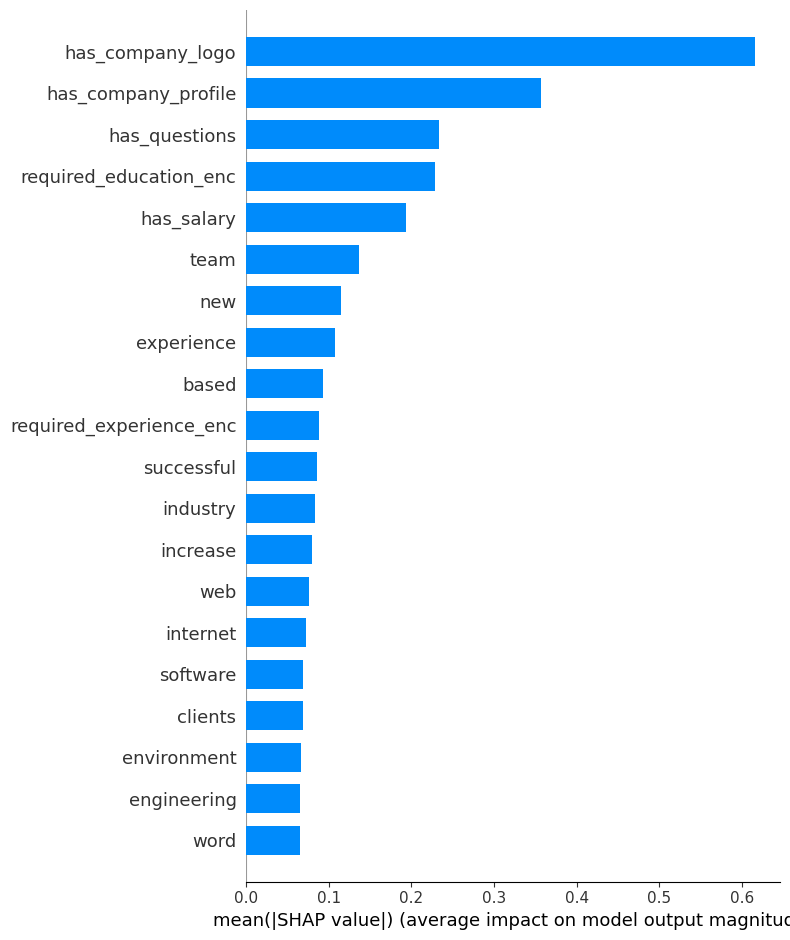

LIME function : 0.851
Actual model  : 0.851


In [25]:
explainer_shap = shap.LinearExplainer(lr_base, X_train_combined_scaled, 
                                       feature_perturbation="interventional")
shap_values = explainer_shap.shap_values(X_test_combined_scaled[:100])

feature_names = tfidf.get_feature_names_out().tolist() + feature_cols
shap.summary_plot(shap_values, X_test_combined_scaled[:100].toarray(),
                  feature_names=feature_names, max_display=20, plot_type='bar')

explainer_lime = LimeTextExplainer(class_names=['Real', 'Fake'])

sample_idx  = y_test[y_test == 1].index[0]
sample_text = X_test_text.loc[sample_idx]
sample_meta = df.loc[sample_idx, feature_cols].values.astype(float).reshape(1, -1)

def predict_proba_text(texts):
    tfidf_vec = tfidf.transform(texts)
    meta = np.repeat(sample_meta, len(texts), axis=0)   # real metadata, constant
    combined = hstack([tfidf_vec, csr_matrix(meta)])
    combined_scaled = scaler.transform(combined)
    return lr_base.predict_proba(combined_scaled)

# check: it must reconcile with the real model's prediction 
pos = X_test_text.index.get_loc(sample_idx)
print("LIME function :", predict_proba_text([sample_text])[0, 1].round(3))
print("Actual model  :", lr_base.predict_proba(X_test_combined_scaled[pos])[0, 1].round(3))

exp = explainer_lime.explain_instance(sample_text, predict_proba_text, num_features=10)
exp.show_in_notebook()

SHAP (computed on the first 100 test postings) shows that structural features dominate the baseline’s predictions: company logo, company profile, screening questions, required education and salary range are the five most influential features, ahead of any individual word. The most influential word is “team”. The bar plot shows average magnitude only, not direction, and the two label-encoded columns (required_education_enc, required_experience_enc) are not directly interpretable.

The LIME explanation for one fake posting in the test set (the explained probability matches the model’s actual prediction of 0.851, with the posting’s real metadata held fixed) shows words pushing toward Fake (“ability”, “professional”, “manner”, “environment”, “assistant”, “motivated”) and words pushing toward Real (“deadlines”, “team”, “join”, “suit”). This is a single example, so it illustrates how the model reads text rather than describing its behaviour in general.

### Advanced NLP Analysis
Beyond surface-level text features, this section looks at sentiment polarity, readability, named entity usage, and recurring phrases that are characteristic of fraudulent postings. The phrases are derived directly from the data rather than predefined manually, which makes the analysis exploratory.

In [26]:
real_texts = df[df['fraudulent'] == 0]['clean_text']
fake_texts = df[df['fraudulent'] == 1]['clean_text']

vec = CountVectorizer(ngram_range=(2,3), max_features=5000)
vec.fit(df['clean_text'])

real_counts = vec.transform(real_texts).sum(axis=0)
fake_counts = vec.transform(fake_texts).sum(axis=0)

vocab = vec.get_feature_names_out()
real_freq = np.asarray(real_counts).flatten() / len(real_texts)
fake_freq = np.asarray(fake_counts).flatten() / len(fake_texts)

ratio = fake_freq / (real_freq + 1e-9)

top_idx = ratio.argsort()[::-1][:20]
print("Top phrases more common in FAKE posts (average occurrences per posting):")
for i in top_idx:
    print(f"{vocab[i]:<40} fake: {fake_freq[i]:.3f}  real: {real_freq[i]:.3f}  ratio: {ratio[i]:.1f}x")

Top phrases more common in FAKE posts (average occurrences per posting):
aker solutions                           fake: 0.173  real: 0.000  ratio: 173210161.7x
aptitude staffing                        fake: 0.124  real: 0.000  ratio: 123556582.0x
people countries                         fake: 0.098  real: 0.001  ratio: 104.4x
go url                                   fake: 0.103  real: 0.001  ratio: 92.0x
oil gas industry                         fake: 0.177  real: 0.002  ratio: 75.1x
systems services                         fake: 0.099  real: 0.002  ratio: 54.5x
business people                          fake: 0.099  real: 0.003  ratio: 38.4x
computer internet                        fake: 0.074  real: 0.002  ratio: 34.9x
good english                             fake: 0.076  real: 0.002  ratio: 30.9x
oil gas                                  fake: 0.241  real: 0.008  ratio: 30.4x
solutions global                         fake: 0.098  real: 0.004  ratio: 25.3x
engineering design              

In [27]:
nlp = spacy.load('en_core_web_sm')

def get_sentiment(text):
    return TextBlob(str(text)).sentiment.polarity

def get_readability(text):
    return textstat.flesch_reading_ease(str(text))

urgent_phrases = [
    'work home',
    'data entry',
    'oil gas',
    'compensation package',
    'referral bonus',
    'computer internet',
    'go url',
    'good english',
    'systems services',
    'business people'
]

def has_urgent_language(text):
    text = str(text).lower()
    return int(any(phrase in text for phrase in urgent_phrases))

def count_org_entities(text):
    doc = nlp(str(text)[:1000])
    return sum(1 for ent in doc.ents if ent.label_ == 'ORG')

def count_money_entities(text):
    doc = nlp(str(text)[:1000])
    return sum(1 for ent in doc.ents if ent.label_ == 'MONEY')

df['sentiment'] = df['description'].apply(get_sentiment)
df['readability'] = df['description'].apply(get_readability)
df['has_urgent_language'] = df['clean_text'].apply(has_urgent_language)
df['org_count'] = df['description'].apply(count_org_entities)
df['money_count'] = df['description'].apply(count_money_entities)

print("Sentiment by class:")
print(df.groupby('fraudulent')['sentiment'].mean().round(3))
print("\nReadability by class:")
print(df.groupby('fraudulent')['readability'].mean().round(3))
print("\nUrgent language by class:")
print(df.groupby('fraudulent')['has_urgent_language'].mean().round(3))
print("\nORG entities by class:")
print(df.groupby('fraudulent')['org_count'].mean().round(3))
print("\nMONEY entities by class:")
print(df.groupby('fraudulent')['money_count'].mean().round(3))

Sentiment by class:
fraudulent
0    0.209
1    0.187
Name: sentiment, dtype: float64

Readability by class:
fraudulent
0    20.226
1    20.298
Name: readability, dtype: float64

Urgent language by class:
fraudulent
0    0.052
1    0.431
Name: has_urgent_language, dtype: float64

ORG entities by class:
fraudulent
0    2.339
1    2.321
Name: org_count, dtype: float64

MONEY entities by class:
fraudulent
0    0.193
1    0.289
Name: money_count, dtype: float64


Advanced NLP analysis yields mixed results across the five dimensions examined.

- Sentiment polarity (0.209 vs 0.187) and readability (20.2 vs 20.3) are very similar across the two classes.
- The phrase-based feature separates the classes best: at least one of the ten selected phrases appears in 43.1% of fake postings versus 5.2% of real ones. Since the phrases were extracted from the full dataset, this gap is likely overstated.
- ORG entity counts (in the first 1,000 characters of each description) are almost identical (2.32 vs 2.34).
- MONEY entities (same limit) are somewhat more frequent in fake postings (0.289 vs 0.193).

The phrase table above also shows that the two most distinctive phrases are company names (“aker solutions” and “aptitude staffing”), which occur on average 0.17 and 0.12 times per fake posting (roughly 150 and 110 occurrences across the 866 fake postings) and essentially never in real ones. This suggests that some fake postings share recurring sources. The ratios for these two rows are not meaningful, since their frequency in real postings is zero.

Of the five features, the phrase-based feature and money entity count show the clearest class differences. They are used here for descriptive analysis only and are not added to the final models, since the phrase list was derived from the full dataset and would leak information if used as a feature.

### Model Comparison Dashboard
A side-by-side comparison of all models on the Fake class (precision, recall, F1 and ROC-AUC) supports the choice of the final model.

                     Precision  Recall     F1  ROC-AUC
Logistic Regression      0.773   0.867  0.817    0.991
Random Forest            1.000   0.584  0.737    0.990
LinearSVC                0.971   0.763  0.854    0.991
DistilBERT               0.909   0.867  0.888    0.990


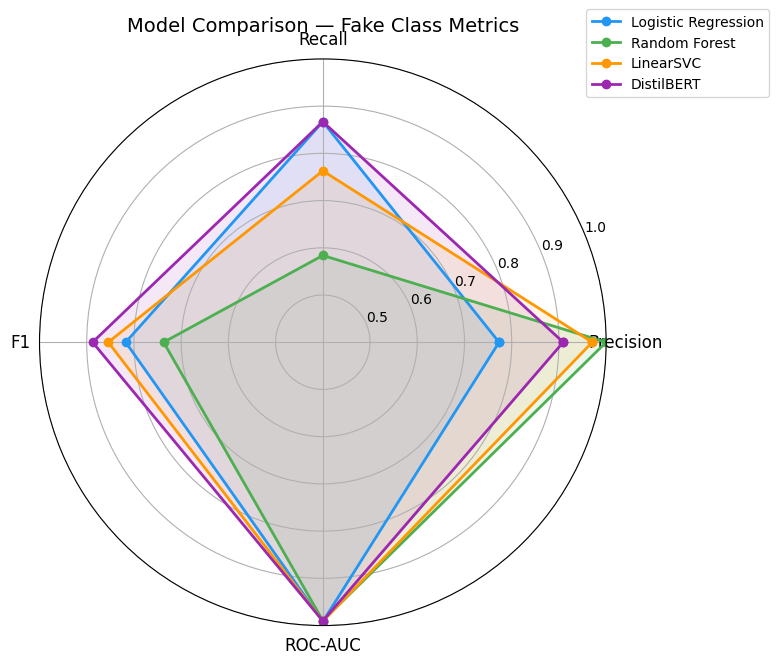

In [28]:
def fake_metrics(y_true, y_pred, y_prob):
    return {
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1':        f1_score(y_true, y_pred),
        'ROC-AUC':   roc_auc_score(y_true, y_prob),
    }

lr  = models['Logistic Regression']   # trained in SCALED features
rf  = models['Random Forest']         # trained in UNSCALED features
svc = models['LinearSVC']             # trained in UNSCALED features

# check: DistilBERT's labels must match with y_test
assert np.array_equal(all_labels, y_test.values), "label order mismatch"

results = {
    'Logistic Regression': fake_metrics(y_test, lr.predict(X_test_combined_scaled),
                                        lr.predict_proba(X_test_combined_scaled)[:, 1]),
    'Random Forest':       fake_metrics(y_test, rf.predict(X_test_combined),
                                        rf.predict_proba(X_test_combined)[:, 1]),
    'LinearSVC':           fake_metrics(y_test, svc.predict(X_test_combined),
                                        svc.predict_proba(X_test_combined)[:, 1]),
    'DistilBERT':          fake_metrics(all_labels, all_preds, all_probs),
}


results_df = pd.DataFrame(results).T.round(3)
print(results_df)

categories = ['Precision', 'Recall', 'F1', 'ROC-AUC']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for (name, metrics), color in zip(results.items(), colors):
    values = [metrics[c] for c in categories]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=12)
ax.set_ylim(0.4, 1.0)
ax.set_title('Model Comparison — Fake Class Metrics', size=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

The comparison table and radar chart show that:

- DistilBERT has the highest F1 (0.888), with precision 0.909 and recall 0.867.
- Random Forest, despite perfect precision, has the weakest recall (0.584) and the lowest F1 (0.737).
- Logistic Regression has the highest recall among the baselines (0.867, the same as DistilBERT) at the cost of precision (0.773), meaning more false alarms; LinearSVC has high precision (0.971) but lower recall (0.763), with the best baseline F1 (0.854).
- ROC-AUC is essentially identical for all models (0.990 to 0.991), so the models differ mainly in how they balance precision and recall.

DistilBERT has the best F1, but its margin over LinearSVC (0.888 vs 0.854) is small given that the test set contains only 173 fake postings. It is selected as the final model, with Logistic Regression retained as a lightweight alternative when inference speed or computational cost matters.

### Advanced Visualizations
Beyond standard metrics, this section looks at the structure of the TF-IDF text representation (t-SNE), the types of errors each model makes (confusion matrices), and how the Logistic Regression baseline scales with training data (learning curve).

Running t-SNE...


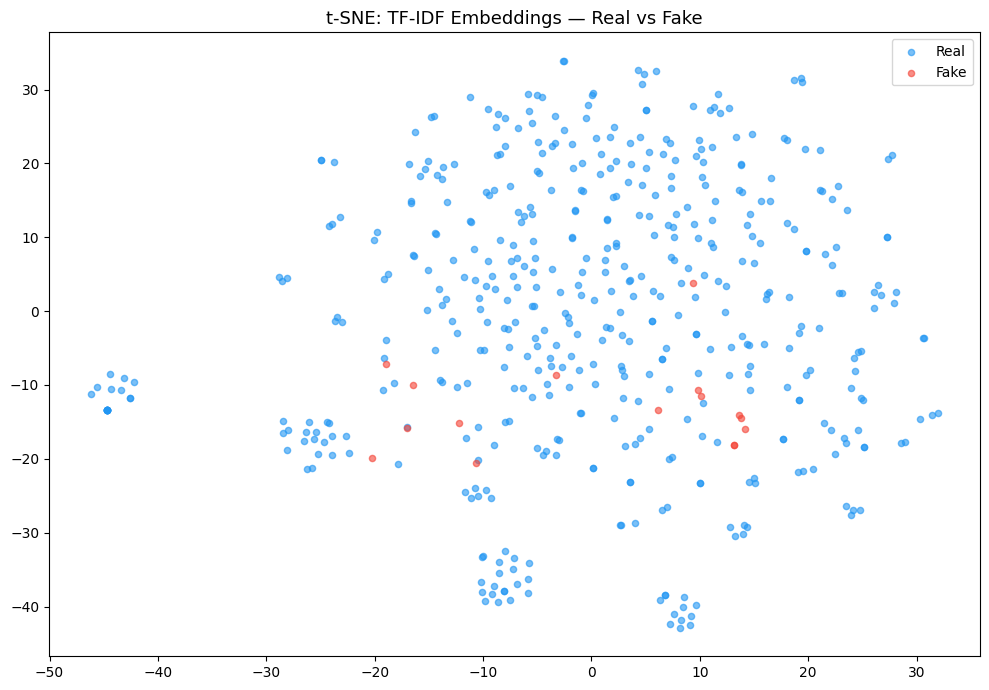

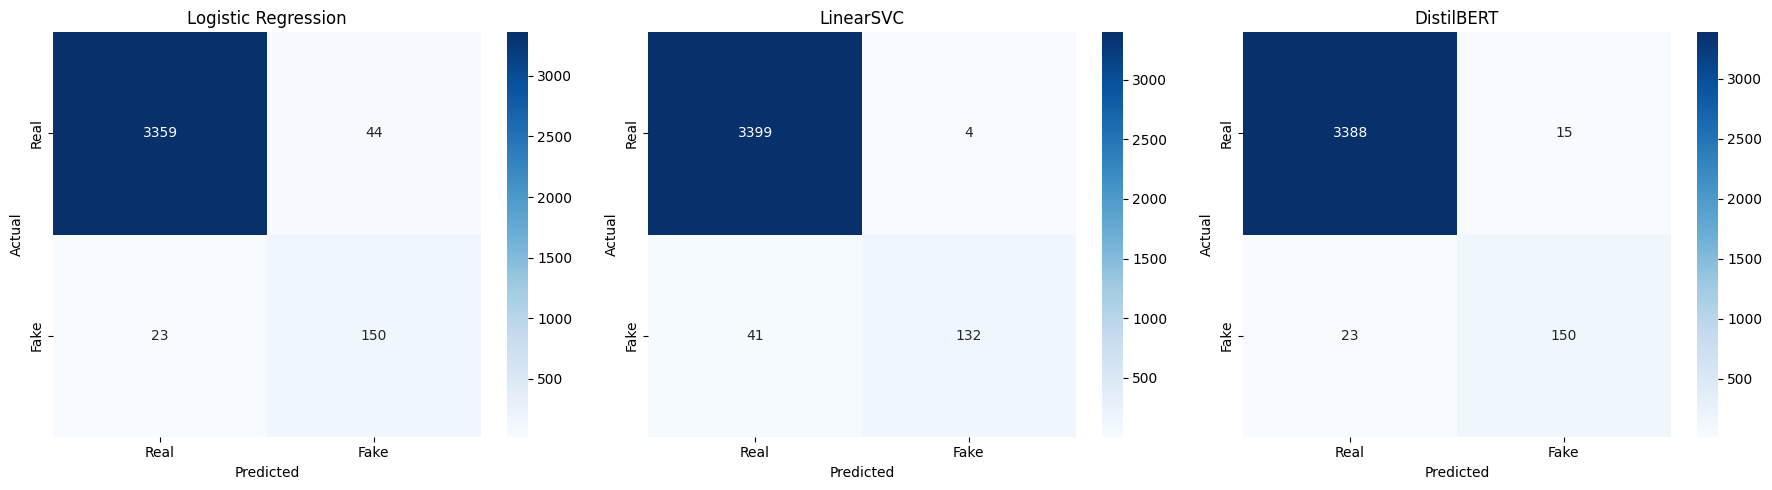

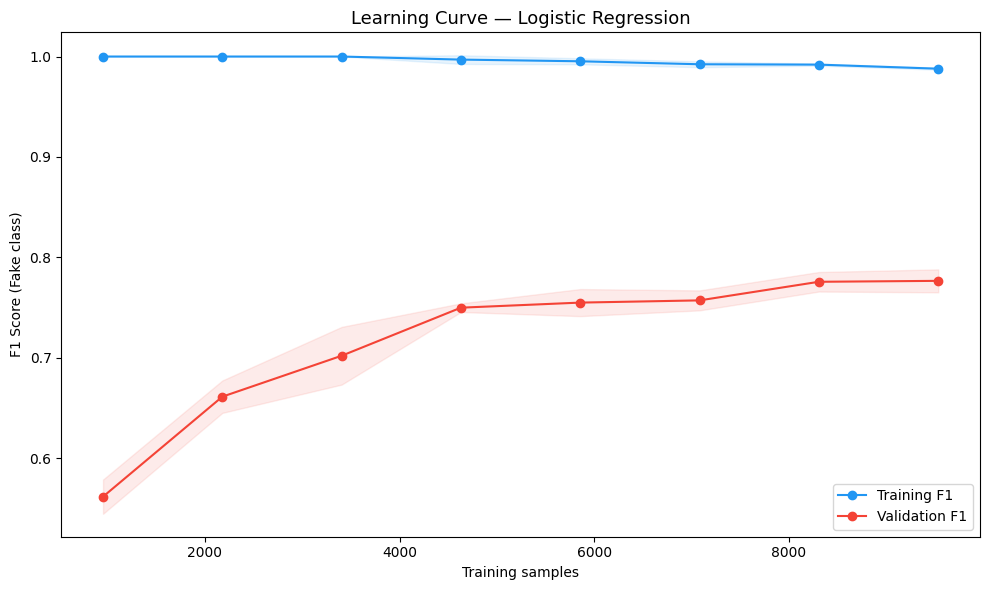

In [29]:
# t-SNE on TF-IDF features
print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_test_tfidf[:500].toarray())

fig, ax = plt.subplots(figsize=(10, 7))
colors = {0: '#2196F3', 1: '#F44336'}
labels_map = {0: 'Real', 1: 'Fake'}
for label in [0, 1]:
    mask = y_test.values[:500] == label
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], 
               c=colors[label], label=labels_map[label], alpha=0.6, s=20)
ax.set_title('t-SNE: TF-IDF Embeddings — Real vs Fake', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_names = ['Logistic Regression', 'LinearSVC', 'DistilBERT']
preds_list = [
    models['Logistic Regression'].predict(X_test_combined_scaled),
    models['LinearSVC'].predict(X_test_combined),
    all_preds
]

for ax, name, preds in zip(axes, model_names, preds_list):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Real', 'Fake'],
                yticklabels=['Real', 'Fake'])
    ax.set_title(name)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

# Learning curves
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    X_train_combined_scaled, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='f1', cv=3, n_jobs=-1
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training F1', color='#2196F3')
ax.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation F1', color='#F44336')
ax.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='#2196F3')
ax.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='#F44336')
ax.set_title('Learning Curve — Logistic Regression', fontsize=13)
ax.set_xlabel('Training samples')
ax.set_ylabel('F1 Score (Fake class)')
ax.legend()
plt.tight_layout()
plt.show()

The t-SNE plot (500 test postings, of which only about 16 are fake) shows fake postings spread among real ones, with a few small groups, so the TF-IDF text alone does not separate them into a distinct cluster.

The confusion matrices show different error profiles. Logistic Regression makes 44 false positives and 23 false negatives, LinearSVC only 4 false positives but 41 false negatives, and DistilBERT 15 false positives and 23 false negatives. In total, that is 67, 45 and 38 errors respectively.

The learning curve shows a large gap between training F1 (about 1.0) and validation F1 (about 0.78), a sign of overfitting in the Logistic Regression model. The validation curve is rising slowly and starting to flatten, so more data may bring modest gains.

### Ablation Study
To compare the contribution of each input type, a Logistic Regression model is trained on one input at a time (title, company profile, description and requirements combined, metadata only, title only, description only) and compared with the model that combines text and metadata. This compares inputs in isolation rather than removing one group at a time from the full model.

In [30]:
def run_ablation(X_train_input, X_test_input, label):
    model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
    scaler_abl = MaxAbsScaler()
    X_train_scaled = scaler_abl.fit_transform(X_train_input)
    X_test_scaled = scaler_abl.transform(X_test_input)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    print(f"{label:<30} F1: {f1:.3f}  Recall: {recall:.3f}")

# Text only
tfidf_abl = TfidfVectorizer(max_features=10000, ngram_range=(1,3))
X_train_text_only = tfidf_abl.fit_transform(X_train_text)
X_test_text_only = tfidf_abl.transform(X_test_text)
run_ablation(X_train_text_only, X_test_text_only, "Text only")

# Metadata only
X_train_meta_only = csr_matrix(X_train_meta)
X_test_meta_only = csr_matrix(X_test_meta)
run_ablation(X_train_meta_only, X_test_meta_only, "Metadata only")

# Title only
tfidf_title = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_title = tfidf_title.fit_transform(df.loc[X_train_text.index, 'title'].fillna(''))
X_test_title = tfidf_title.transform(df.loc[X_test_text.index, 'title'].fillna(''))
run_ablation(X_train_title, X_test_title, "Title only")

# Description only
tfidf_desc = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_desc = tfidf_desc.fit_transform(df.loc[X_train_text.index, 'description'].fillna(''))
X_test_desc = tfidf_desc.transform(df.loc[X_test_text.index, 'description'].fillna(''))
run_ablation(X_train_desc, X_test_desc, "Description only")

# All combined
run_ablation(X_train_combined, X_test_combined, "All combined")

Text only                      F1: 0.833  Recall: 0.850
Metadata only                  F1: 0.247  Recall: 0.618
Title only                     F1: 0.494  Recall: 0.775
Description only               F1: 0.665  Recall: 0.775
All combined                   F1: 0.817  Recall: 0.867


Text carries most of the predictive signal. Text alone reaches F1 0.833 and recall 0.850, slightly higher on F1 than the full model (0.817, recall 0.867); these differences are small relative to the F1 uncertainty of about ±0.04 on this test set. Metadata alone performs poorly (F1 0.247): it still catches 61.8% of fake postings, but with very low precision. The title alone gives F1 0.494 and the description alone 0.665, reflecting the richer content of the description. Adding metadata to the text therefore does not clearly improve the Logistic Regression model in this experiment.

### Cross-validation & Robustness
A single train/test split may not reflect model stability. Stratified K-Fold cross-validation on the training set shows how results vary across data subsets, a bootstrap confidence interval shows how uncertain the test-set F1 is, and a calibration curve shows how well the predicted probabilities match observed frequencies. All three are computed for the Logistic Regression baseline.

Stratified K-Fold (5 folds) — Logistic Regression:
F1:     0.784 ± 0.028
Recall: 0.837 ± 0.043


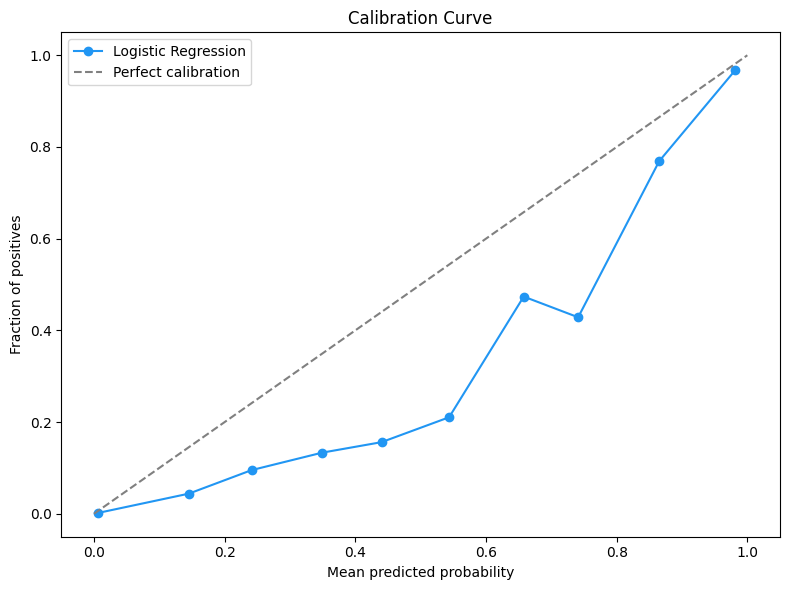


Bootstrap 95% CI for F1: [0.776, 0.858]


In [31]:
# Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

f1_scores = cross_val_score(lr_cv, X_train_combined_scaled, y_train, 
                             cv=skf, scoring='f1')
recall_scores = cross_val_score(lr_cv, X_train_combined_scaled, y_train, 
                                cv=skf, scoring='recall')

print("Stratified K-Fold (5 folds) — Logistic Regression:")
print(f"F1:     {f1_scores.mean():.3f} ± {f1_scores.std():.3f}")
print(f"Recall: {recall_scores.mean():.3f} ± {recall_scores.std():.3f}")

# Calibration curve
lr_cal = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_cal.fit(X_train_combined_scaled, y_train)
y_prob_cal = lr_cal.predict_proba(X_test_combined_scaled)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob_cal, n_bins=10)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(prob_pred, prob_true, 'o-', label='Logistic Regression', color='#2196F3')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration Curve')
ax.legend()
plt.tight_layout()
plt.show()

# Bootstrap confidence intervals
np.random.seed(42)
n_bootstrap = 1000
f1_bootstrap = []

for _ in range(n_bootstrap):
    y_test_bs, y_pred_bs = resample(y_test.values, 
                                     lr_cal.predict(X_test_combined_scaled), 
                                     random_state=None)
    f1_bootstrap.append(f1_score(y_test_bs, y_pred_bs))

ci_lower = np.percentile(f1_bootstrap, 2.5)
ci_upper = np.percentile(f1_bootstrap, 97.5)
print(f"\nBootstrap 95% CI for F1: [{ci_lower:.3f}, {ci_upper:.3f}]")

Stratified 5-fold cross-validation on the training set gives F1 0.784 ± 0.028 and recall 0.837 ± 0.043, showing moderate variation across folds. The test-set F1 of the same model (0.817) lies within the bootstrap 95% confidence interval [0.776, 0.858], which indicates how uncertain a single test estimate is with only 173 fake postings (it reflects test-set sampling only).

The calibration curve shows that the class-weighted Logistic Regression over-estimates fraud probabilities over most of the range: postings assigned about 50% probability are fraudulent only around 15–20% of the time. This is consistent with the effect of class weighting, which shifts predicted probabilities as if the classes were balanced. The model is well calibrated near 0 and near 1. Ranking by predicted probability is not affected by this, but the probabilities should not be read as literal fraud rates unless they are recalibrated.

### Evaluation & Error Analysis
Beyond aggregate metrics, this section looks at the ROC curves of the three models and at the specific postings that the Logistic Regression baseline misclassifies, to understand its limitations.

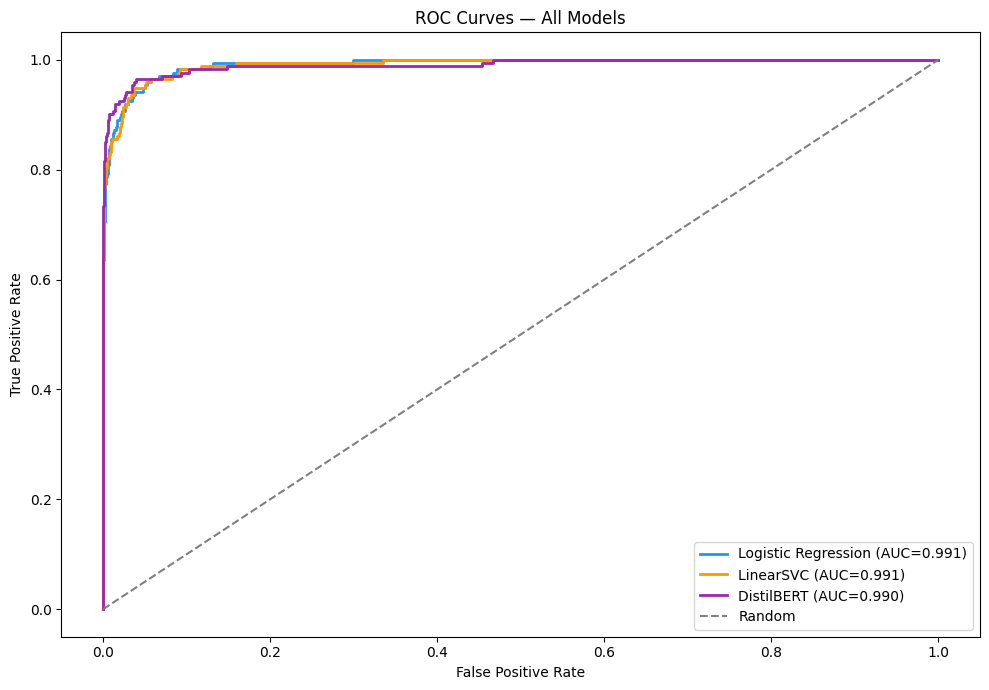

False Negatives (fake that escaped): 23
False Positives (real flagged wrong): 44

False Negatives — avg features:
has_company_logo         0.217
has_company_profile      0.261
has_salary               0.391
word_count             146.174
dtype: float64

False Positives — avg features:
has_company_logo         0.136
has_company_profile      0.000
has_salary               0.432
word_count             142.591
dtype: float64

Sample False Negative titles:
['Vemma Brand Partner' 'Subsea Installation Engineer'
 'Fraud Detection Analyst' 'RNFA Registered Nurse First Assistant  '
 'Real Estate & Insurance Professionals']

Sample False Positive titles:
['Joomla Developer' 'SCIENTIFIC REPRESENTATIVE (SALES REP)'
 'Software Project Manager'
 'Customer support for e-shop with decorative objects. '
 'Controls Engineer- Programming & Debug of PLC- Automotive Environment']


In [32]:
# ROC curves
fig, ax = plt.subplots(figsize=(10, 7))

model_probs = {
    'Logistic Regression': models['Logistic Regression'].predict_proba(X_test_combined_scaled)[:, 1],
    'LinearSVC': models['LinearSVC'].predict_proba(X_test_combined)[:, 1],
    'DistilBERT': all_probs
}
colors = {'Logistic Regression': '#2196F3', 'LinearSVC': '#FF9800', 'DistilBERT': '#9C27B0'}

for name, probs in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=colors[name], linewidth=2)

ax.plot([0, 1], [0, 1], '--', color='gray', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models')
ax.legend()
plt.tight_layout()
plt.show()

# False Negatives & False Positives analysis
lr_preds = models['Logistic Regression'].predict(X_test_combined_scaled)
test_df = df.loc[X_test_text.index].copy()
test_df['predicted'] = lr_preds

fn = test_df[(test_df['fraudulent'] == 1) & (test_df['predicted'] == 0)]
fp = test_df[(test_df['fraudulent'] == 0) & (test_df['predicted'] == 1)]

print(f"False Negatives (fake that escaped): {len(fn)}")
print(f"False Positives (real flagged wrong): {len(fp)}")

print("\nFalse Negatives — avg features:")
print(fn[['has_company_logo', 'has_company_profile', 'has_salary', 'word_count']].mean().round(3))

print("\nFalse Positives — avg features:")
print(fp[['has_company_logo', 'has_company_profile', 'has_salary', 'word_count']].mean().round(3))

print("\nSample False Negative titles:")
print(fn['title'].head(5).values)

print("\nSample False Positive titles:")
print(fp['title'].head(5).values)

The ROC curves of the three models almost coincide (AUC 0.991 for Logistic Regression and LinearSVC, 0.990 for DistilBERT), so they cannot be separated on ranking quality alone.

Error analysis on the Logistic Regression model finds 23 false negatives and 44 false positives. The 23 missed fake postings have a logo in 21.7% and a company profile in 26.1% of cases, no higher than the average fake posting (32.7% and 32.2%), so their structure does not mimic legitimate listings; they differ mainly by more frequent salary ranges (39.1% vs 25.8%) and shorter text (146 vs 181 words on average), and their titles look like ordinary job titles. The 44 false positives all lack a company profile, rarely have a logo (13.6%) and are short (143 words on average vs 236 for real postings), so structurally they resemble fake postings. The error analysis covers the Logistic Regression baseline only. With so few cases, these patterns are descriptive and should not be generalised.

### Business Framing
Technical metrics alone do not show the cost of model errors. Using illustrative costs for each error type, this section translates the Logistic Regression baseline’s results into business terms and compares its cost with that of DistilBERT.

In [33]:
# Cost-benefit analysis
total_fake = y_test.sum()
total_real = len(y_test) - total_fake

lr_preds = models['Logistic Regression'].predict(X_test_combined_scaled)
tn = ((y_test == 0) & (lr_preds == 0)).sum()
fp = ((y_test == 0) & (lr_preds == 1)).sum()
fn = ((y_test == 1) & (lr_preds == 0)).sum()
tp = ((y_test == 1) & (lr_preds == 1)).sum()

cost_fn = 100  # cost of a fake posting that slips through (high)
cost_fp = 10   # cost of a real posting wrongly flagged (low)

total_cost = fn * cost_fn + fp * cost_fp
no_model_cost = total_fake * cost_fn

print("=== Cost-Benefit Analysis (Logistic Regression) ===")
print(f"True Positives  (caught fake):         {tp}")
print(f"False Negatives (missed fake):         {fn}  — cost: {fn * cost_fn}")
print(f"False Positives (wrongly flagged real): {fp}  — cost: {fp * cost_fp}")
print(f"\nTotal cost with model:    {total_cost}")
print(f"Total cost without model: {no_model_cost}")
print(f"Cost reduction:           {((no_model_cost - total_cost) / no_model_cost * 100):.1f}%")

print("\n=== Business Impact ===")
print(f"Fraudulent postings in test set:      {total_fake}")
print(f"Detected by model:                    {tp} ({tp/total_fake*100:.1f}%)")
print(f"Missed by model:                      {fn} ({fn/total_fake*100:.1f}%)")
print(f"\nIf scaled to 1M job postings with 4.8% fraud rate:")
fake_1m = int(1_000_000 * 0.048)
caught_1m = int(fake_1m * (tp/total_fake))
missed_1m = fake_1m - caught_1m
print(f"Total fake postings:  {fake_1m:,}")
print(f"Caught by model:      {caught_1m:,}")
print(f"Missed by model:      {missed_1m:,}")

# Real postings wrongly flagged, scaled to 1M postings
real_1m = 1_000_000 - fake_1m
flagged_real_1m = int(real_1m * fp / total_real)
print(f"Real postings wrongly flagged: {flagged_real_1m:,}")

# Same cost analysis for DistilBERT
db_preds = np.array(all_preds)
fn_db = ((y_test.values == 1) & (db_preds == 0)).sum()
fp_db = ((y_test.values == 0) & (db_preds == 1)).sum()
cost_db = fn_db * cost_fn + fp_db * cost_fp
print(f"\n=== Cost-Benefit Analysis (DistilBERT) ===")
print(f"False Negatives: {fn_db}  — cost: {fn_db * cost_fn}")
print(f"False Positives: {fp_db}  — cost: {fp_db * cost_fp}")
print(f"Total cost with model: {cost_db}")
print(f"Cost reduction:        {((no_model_cost - cost_db) / no_model_cost * 100):.1f}%")

=== Cost-Benefit Analysis (Logistic Regression) ===
True Positives  (caught fake):         150
False Negatives (missed fake):         23  — cost: 2300
False Positives (wrongly flagged real): 44  — cost: 440

Total cost with model:    2740
Total cost without model: 17300
Cost reduction:           84.2%

=== Business Impact ===
Fraudulent postings in test set:      173
Detected by model:                    150 (86.7%)
Missed by model:                      23 (13.3%)

If scaled to 1M job postings with 4.8% fraud rate:
Total fake postings:  48,000
Caught by model:      41,618
Missed by model:      6,382
Real postings wrongly flagged: 12,309

=== Cost-Benefit Analysis (DistilBERT) ===
False Negatives: 23  — cost: 2300
False Positives: 15  — cost: 150
Total cost with model: 2450
Cost reduction:        85.8%


Using illustrative costs (100 per missed fake posting, 10 per real posting wrongly flagged), the Logistic Regression model reduces total cost by 84.2% relative to a no-model baseline in which all fraud goes undetected (2,740 vs 17,300). It catches 86.7% of the fake postings in the test set (150 of 173) and misses 23. These figures depend entirely on the assumed costs.

Scaled to 1 million postings with the same fraud rate and error rates as in the test set, the model would intercept about 41,600 fake listings and miss about 6,400, but it would also flag roughly 12,300 genuine postings (1.3% of real ones) that would need review.

For comparison, DistilBERT (23 false negatives, 15 false positives) has a cost of 2,450 under the same assumptions, an 85.8% reduction. The difference from Logistic Regression (2,740) is modest and rests on the assumed costs, so the choice between the two should also consider inference cost and speed.

### Deployment: Gradio App
An interactive demo makes the model easy to try. The app accepts a job posting and returns a fraud probability and a classification. It serves the Logistic Regression baseline through a temporary public Gradio link (valid for one week); a permanent deployment, for example on Hugging Face Spaces, is future work.

In [34]:
!pip install gradio -q

import gradio as gr

def predict_fraud(title, company_profile, description, requirements, has_logo, has_salary):
    
    combined = f"{title} {company_profile} {description} {requirements}"
    clean = clean_text(combined)
    
    tfidf_input = tfidf.transform([clean])
    
    meta_input = np.array([[
        len(clean.split()),
        np.mean([len(w) for w in clean.split()]) if clean.split() else 0,
        sum(1 for c in combined if c.isupper()),
        int(has_salary),
        int(bool(company_profile)),
        int(bool(requirements)),
        0,  # has_benefits
        0,  # telecommuting
        int(has_logo),
        0,  # has_questions
        1,  # employment_type_enc default
        4,  # required_experience_enc default
        5   # required_education_enc default
    ]])
    
    combined_input = hstack([tfidf_input, csr_matrix(meta_input)])
    combined_scaled = scaler.transform(combined_input)
    
    prob = models['Logistic Regression'].predict_proba(combined_scaled)[0][1]
    label = "🚨 FAKE" if prob >= 0.5 else "✅ REAL"  # default 0.5 threshold, as in the baseline
    
    return f"{label}\nFraud probability: {prob:.1%}"

demo = gr.Interface(
    fn=predict_fraud,
    inputs=[
        gr.Textbox(label="Job Title", placeholder="e.g. Marketing Manager"),
        gr.Textbox(label="Company Profile", placeholder="Brief company description..."),
        gr.Textbox(label="Job Description", lines=4, placeholder="Job description..."),
        gr.Textbox(label="Requirements", lines=3, placeholder="Requirements..."),
        gr.Checkbox(label="Has Company Logo"),
        gr.Checkbox(label="Has Salary Range")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Job Posting Fraud Detector",
    description=("Interactive demo of the Logistic Regression baseline (TF-IDF + metadata). "
             "Fields not shown (benefits, telecommuting, screening questions, employment type, "
             "experience, education) are set to default values, which can bias predictions "
             "slightly toward 'fake'. Demo for illustration only.")
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://e8b27424de1c8fb198.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
